# TexMM · VGG19 · LAMB recipe — augmentation: off (resize only)

Image-only VGG19 with the paper-aligned recipe (comparable to the TexMM paper's 51.38% image-only ResNet50 baseline (Kim & Chi, ICASSP 2026, Table 1)). Fixed parts of the recipe:

| | This notebook | Earlier ADAM/weighted notebooks |
|---|---|---|
| Optimiser | **LAMB** (lr 1e-3, weight-decay 0.01) | Adam |
| Schedule | CosineAnnealingLR (lr → 1e-6), **end-to-end** | two-stage: head 1e-3 → fine-tune 1e-4, cosine |
| Loss | **unweighted** BCEWithLogits | weighted (inverse-freq) |
| Augmentation | **off (resize only)** | full (crop + colour jitter + noise) |

ImageNet-pretrained · batch 32 · 448×448 · exact-match (subset)
accuracy. Aggressive augmentation was tested and *lowered* accuracy on this fine-grained task (it destroys weave/colour cues), so it is left off. The Eval cell reports at threshold **0.5**; the Threshold-tuning cell then searches
the cut-off as a separate enhancement. **High-resolution config:** input upscaled to 448x448; ImageNet1K_V1 weights (V2 exists only for ResNet50). Batch 32 fits a ~22 GB GPU for DenseNet-121 and EfficientNet-B0; for VGG19 at 448px lower BATCH_SIZE if you hit OOM.

**Dataset – TexMM** (`MyDrive/TexMM_Local`): pre-split train/test; the 20% test split is used as the validation set reported here. Labels `*_y.npy` (N,10,12) collapsed with `max` → (N,12). 3 views/sample aggregated at eval.


## 1 · Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## 2 · Configuration

In [ ]:
# ===== CONFIG  (edit these to complete / tweak the report settings) =====
RANDOM_SEED = 42
IMG_SIZE = 448
BATCH_SIZE = 16
NUM_WORKERS = 2
THRESHOLD = 0.5
USE_SSD = True
BACKBONE = 'vgg19'
REGIME = 'transfer'
WEIGHTED = False
AUGMENT = False
LR = 0.001
WEIGHT_DECAY = 0.01
EPOCHS = 40
EARLY_STOP_PATIENCE = 10
VAL_SPLIT = 0.2
CROP_SCALE = (0.6, 1.0)
CROP_RATIO = (0.9, 1.1)
ROTATION_DEG = 15
CONTRAST_JITTER = 0.2
SATURATION_JITTER = 0.2
GAUSSIAN_NOISE_STD = 0.01
RUN_NAME = 'TexMM | VGG19 | LAMB recipe | aug: off (resize only)'
RUN_TAG = 'texmm_vgg19_lamb_hires448_cosine'
CKPT_PATH = '/content/texmm_vgg19_lamb_hires448_cosine.pt'
SAVE_DIR = '/content/drive/MyDrive/TexMM_Local'
DRIVE_TEXMM = '/content/drive/MyDrive/TexMM_Local'

## 3 · Imports, seeds, device

In [ ]:
import os, re, math, random, shutil, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, hamming_loss, classification_report)

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED); torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, (torch.cuda.get_device_name(0) if DEVICE == 'cuda' else ''))

Device: cuda NVIDIA L4


## 4 · Copy dataset to local SSD

In [ ]:
def copy_to_ssd(src, dst, workers=16):
    '''Copy a Drive folder to the local Colab NVMe once (skips already-copied files).'''
    if not os.path.isdir(src):
        raise FileNotFoundError(
            'Drive source not found: ' + src +
            '\nIf the folder is under "Shared with me", right-click it -> '
            'Add shortcut to Drive -> My Drive, then fix the path in CONFIG.')
    for root, _, _ in os.walk(src):
        os.makedirs(root.replace(src, dst, 1), exist_ok=True)
    files = [(os.path.join(r, f), os.path.join(r, f).replace(src, dst, 1))
             for r, _, fs in os.walk(src) for f in fs]
    todo = [(s, d) for s, d in files if not os.path.exists(d)]
    print(f'{src} -> {dst} | total {len(files)} | to copy {len(todo)}')

    def _one(a):
        s, d = a
        for k in range(4):
            try:
                shutil.copy2(s, d); return True
            except OSError as e:
                if k == 3:
                    return f'FAIL {os.path.basename(s)} [{e}]'
                time.sleep(3)

    t0 = time.time(); ok = bad = 0
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i, fut in enumerate(as_completed([ex.submit(_one, x) for x in todo])):
            r = fut.result()
            if r is True: ok += 1
            else: bad += 1; print('  ', r)
            if (i + 1) % 500 == 0:
                print(f'  {i+1}/{len(todo)}  ok={ok} bad={bad}')
    print(f'done in {(time.time()-t0)/60:.1f} min | ok={ok} bad={bad}')
    return dst

## 5 · Load dataset & labels

In [ ]:
TEXMM_DIR = copy_to_ssd(DRIVE_TEXMM, '/content/TexMM_Local') if USE_SSD else DRIVE_TEXMM

train_y = np.load(os.path.join(TEXMM_DIR, 'train_y.npy')).max(axis=1).astype(np.float32)
val_y   = np.load(os.path.join(TEXMM_DIR, 'test_y.npy')).max(axis=1).astype(np.float32)

def _paths(csv):
    raw = open(os.path.join(TEXMM_DIR, csv)).read()
    return [p.strip().lstrip('./') for p in raw.split(',') if p.strip()]

train_paths = _paths('train_direct_list.csv')
val_paths   = _paths('test_direct_list.csv')   # provided 20% test = the validation split (Table 3)

CLASS_NAMES = ['SP', 'CA', 'L', 'R', 'M', 'TEN', 'P', 'W', 'N', 'A', 'S', 'C']

def _recs(paths, ys):
    out, miss = [], 0
    for rp, l in zip(paths, ys):
        ip = os.path.join(TEXMM_DIR, rp)
        sid = re.sub(r'\(\d+\)\.[^/]+$', '', rp)
        if os.path.isfile(ip): out.append((ip, l, sid))
        else: miss += 1
    if miss: print('  missing images:', miss)
    return out

train_records = _recs(train_paths, train_y)
val_records   = _recs(val_paths, val_y)

/content/drive/MyDrive/TexMM_Local -> /content/TexMM_Local | total 9203 | to copy 0
done in 0.0 min | ok=0 bad=0


In [ ]:
# Keep only classes that actually occur (>=1 positive) across the loaded data.
# (For NIST this automatically reduces the 12 label columns to the ~8 present classes.)
def finalize_classes(record_lists, class_names):
    M = np.stack([r[1] for rs in record_lists for r in rs])
    keep = [i for i, c in enumerate(class_names) if M[:, i].sum() > 0]
    kept = [class_names[i] for i in keep]
    dropped = [c for c in class_names if c not in kept]
    if dropped:
        print('Dropping empty classes:', dropped)
    out = [[(p, l[keep].astype(np.float32), s) for (p, l, s) in rs] for rs in record_lists]
    return out, kept

(train_records, val_records), CLASSES = finalize_classes([train_records, val_records], CLASS_NAMES)
NUM_CLASSES = len(CLASSES)
n_tr = len({r[2] for r in train_records}); n_va = len({r[2] for r in val_records})
print(f'Classes ({NUM_CLASSES}): {CLASSES}')
print(f'Train: {len(train_records)} imgs / {n_tr} samples | Val: {len(val_records)} imgs / {n_va} samples')

Classes (12): ['SP', 'CA', 'L', 'R', 'M', 'TEN', 'P', 'W', 'N', 'A', 'S', 'C']
Train: 6850 imgs / 2284 samples | Val: 1691 imgs / 565 samples


## 6 · Transforms & DataLoaders

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class AddGaussianNoise:
    def __init__(self, std=0.01): self.std = std
    def __call__(self, t): return t + torch.randn_like(t) * self.std

eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

if AUGMENT:
    train_tf = T.Compose([
        T.RandomResizedCrop(IMG_SIZE, scale=CROP_SCALE, ratio=CROP_RATIO),
        T.RandomHorizontalFlip(),
        T.RandomVerticalFlip(),
        T.RandomRotation(ROTATION_DEG),
        T.ColorJitter(contrast=CONTRAST_JITTER, saturation=SATURATION_JITTER),
        T.ToTensor(), T.Normalize(MEAN, STD), AddGaussianNoise(GAUSSIAN_NOISE_STD),
    ])
else:
    train_tf = eval_tf

class TextileDataset(Dataset):
    def __init__(self, records, tf): self.records = records; self.tf = tf
    def __len__(self): return len(self.records)
    def __getitem__(self, i):
        p, l, s = self.records[i]
        return self.tf(Image.open(p).convert('RGB')), torch.tensor(l, dtype=torch.float32), s

train_loader = DataLoader(TextileDataset(train_records, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(TextileDataset(val_records, eval_tf), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

eval_loader = val_loader
print(f'Batches | train {len(train_loader)} | val {len(val_loader)}')

Batches | train 429 | val 106


## 7 · Model (ImageNet-pretrained)

In [ ]:
def build_backbone(name, pretrained):
    name = name.lower()
    if name == 'resnet50':
        w = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet50(weights=w); in_f = net.fc.in_features; net.fc = nn.Identity()
    elif name == 'vgg19':
        w = models.VGG19_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.vgg19(weights=w); in_f = net.classifier[0].in_features; net.classifier = nn.Identity()
    elif name == 'densenet121':
        w = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.densenet121(weights=w); in_f = net.classifier.in_features; net.classifier = nn.Identity()
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.efficientnet_b0(weights=w); in_f = net.classifier[1].in_features; net.classifier = nn.Identity()
    else:
        raise ValueError('Unknown BACKBONE: ' + name)
    return net, in_f

class TextileCNN(nn.Module):
    def __init__(self, backbone_name, num_classes, pretrained):
        super().__init__()
        self.backbone, in_f = build_backbone(backbone_name, pretrained)
        self.classifier = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(in_f, 512), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(512, num_classes))
    def forward(self, x): return self.classifier(self.backbone(x))
    def set_backbone_trainable(self, flag):
        for p in self.backbone.parameters(): p.requires_grad = flag

PRETRAINED = (REGIME == 'transfer')
model = TextileCNN(BACKBONE, NUM_CLASSES, PRETRAINED).to(DEVICE)
print(f'{BACKBONE} | {sum(p.numel() for p in model.parameters()):,} params | '
      f'regime={REGIME} | pretrained={PRETRAINED}')

vgg19 | 32,876,108 params | regime=transfer | pretrained=True


## 8 · Loss

In [ ]:
# Paper uses a plain (unweighted) multi-label BCE -- eq. (11).
criterion = nn.BCEWithLogitsLoss()
print('Loss: unweighted BCEWithLogits (paper recipe)')

Loss: unweighted BCEWithLogits (paper recipe)


## 9 · Optimiser (LAMB)

In [ ]:
class Lamb(torch.optim.Optimizer):
    '''Minimal LAMB optimiser (You et al., 2019) -- the optimiser used in the TexMM paper.
    LAMB = Adam moments + decoupled weight decay + per-layer trust-ratio scaling.'''
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-6, weight_decay=0.01):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for grp in self.param_groups:
            b1, b2 = grp['betas']
            for p in grp['params']:
                if p.grad is None: continue
                g, st = p.grad, self.state[p]
                if not st:
                    st['step'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['step'] += 1
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                mhat = st['m'] / (1 - b1 ** st['step'])
                vhat = st['v'] / (1 - b2 ** st['step'])
                upd = mhat / (vhat.sqrt() + grp['eps'])
                if grp['weight_decay'] != 0:
                    upd = upd.add(p, alpha=grp['weight_decay'])
                wn, un = p.norm(), upd.norm()
                trust = (wn / un).item() if (wn > 0 and un > 0) else 1.0
                p.add_(upd, alpha=-grp['lr'] * trust)
        return loss

## 10 · Training (LAMB + cosine annealing, end-to-end)

In [ ]:
def exact_match(L, P): return float(np.all(L == P, axis=1).mean())

def run_epoch(loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot, Ps, Ls = 0.0, [], []
    with torch.set_grad_enabled(train):
        for imgs, labels, _ in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            logits = model(imgs); loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item() * len(imgs)
            Ps.append((torch.sigmoid(logits) > THRESHOLD).cpu().numpy().astype(int))
            Ls.append(labels.cpu().numpy().astype(int))
    P, L = np.vstack(Ps), np.vstack(Ls)
    return tot / len(loader.dataset), exact_match(L, P), f1_score(L, P, average='micro', zero_division=0)

# ImageNet-pretrained backbone fine-tuned END-TO-END with LAMB + CosineAnnealingLR (no restarts),
# unweighted BCE. Best checkpoint by validation subset accuracy.
ETA_MIN = 1e-6
model.set_backbone_trainable(True)
opt = Lamb(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=ETA_MIN)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_score, best_acc, best_epoch, since = -1.0, 0.0, 0, 0
print(f'LAMB + CosineAnnealingLR | lr={LR:.1e} -> {ETA_MIN:.0e} | weight_decay={WEIGHT_DECAY} | end-to-end | max {EPOCHS} epochs\n')
print(f'{"Ep":>3} {"LR":>9} {"TrLoss":>8} {"TrAcc%":>7} {"TrF1u":>6} {"VaLoss":>8} {"VaAcc%":>7} {"VaF1u":>6}')
for ep in range(1, EPOCHS + 1):
    cur_lr = opt.param_groups[0]['lr']
    tl, ta, tf = run_epoch(train_loader, opt)
    vl, va, vf = run_epoch(val_loader, None)
    sched.step()
    history['train_loss'].append(tl); history['val_loss'].append(vl)
    history['train_acc'].append(ta);  history['val_acc'].append(va)
    history['train_f1'].append(tf);   history['val_f1'].append(vf)
    score = va + 1e-3 * vf
    flag = ''
    if score > best_score:
        best_score, best_acc, best_epoch, since = score, va, ep, 0
        torch.save({'model_state': model.state_dict(), 'classes': CLASSES,
                    'val_acc': va, 'val_f1': vf}, CKPT_PATH)
        flag = ' *'
    else:
        since += 1
    print(f'{ep:>3} {cur_lr:>9.2e} {tl:>8.4f} {ta*100:>7.2f} {tf:>6.3f} {vl:>8.4f} {va*100:>7.2f} {vf:>6.3f}{flag}')
    if since >= EARLY_STOP_PATIENCE:
        print(f'  early stop: no val-accuracy gain for {EARLY_STOP_PATIENCE} epochs'); break

print(f'\nBest val accuracy = {best_acc*100:.2f}% (epoch {best_epoch})')

LAMB + CosineAnnealingLR | lr=1.0e-03 -> 1e-06 | weight_decay=0.01 | end-to-end | max 40 epochs

 Ep        LR   TrLoss  TrAcc%  TrF1u   VaLoss  VaAcc%  VaF1u
  1  1.00e-03   0.2606   26.82  0.605   0.2622   28.33  0.571 *
  2  9.98e-04   0.1924   44.63  0.742   0.2367   40.51  0.645 *
  3  9.94e-04   0.1553   53.49  0.800   0.1982   45.12  0.703 *
  4  9.86e-04   0.1300   59.59  0.835   0.2297   37.02  0.648
  5  9.76e-04   0.1131   64.50  0.860   0.2538   34.95  0.656
  6  9.62e-04   0.0978   69.72  0.883   0.2407   44.47  0.709
  7  9.46e-04   0.0838   73.04  0.900   0.2182   48.26  0.710 *
  8  9.26e-04   0.0740   75.81  0.913   0.2348   41.34  0.702
  9  9.05e-04   0.0646   78.55  0.923   0.2783   41.40  0.695
 10  8.80e-04   0.0537   81.27  0.935   0.2776   45.18  0.715
 11  8.54e-04   0.0464   83.81  0.945   0.2927   44.53  0.708
 12  8.25e-04   0.0400   86.06  0.954   0.2989   44.71  0.704
 13  7.94e-04   0.0333   87.69  0.961   0.3614   46.84  0.705
 14  7.61e-04   0.0293   89

## 11 · Training curves

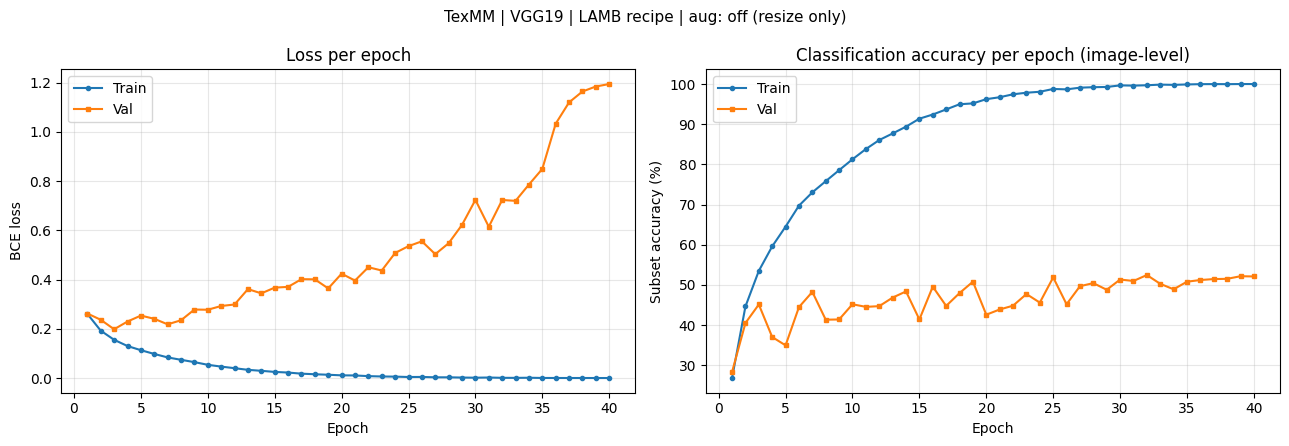

In [ ]:
ep = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, history['train_loss'], 'o-', ms=3, label='Train')
axes[0].plot(ep, history['val_loss'],   's-', ms=3, label='Val')
axes[0].set_title('Loss per epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a * 100 for a in history['train_acc']], 'o-', ms=3, label='Train')
axes[1].plot(ep, [a * 100 for a in history['val_acc']],   's-', ms=3, label='Val')
axes[1].set_title('Classification accuracy per epoch (image-level)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Subset accuracy (%)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle(RUN_NAME, fontsize=11); plt.tight_layout()
plt.savefig('/content/curves.png', dpi=150, bbox_inches='tight'); plt.show()

## 12 · Sample-level evaluation (threshold 0.5)  ← report row

In [ ]:
# Reload best checkpoint (selected by validation accuracy), evaluate at SAMPLE level:
# average view probabilities -> threshold.
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state'])
print(f"Best checkpoint val accuracy = {ckpt['val_acc']*100:.2f}%")

model.eval()
sp, sl = defaultdict(list), {}
with torch.no_grad():
    for imgs, labels, sids in eval_loader:
        pr = torch.sigmoid(model(imgs.to(DEVICE))).cpu().numpy()
        for sid, p, l in zip(sids, pr, labels.numpy()):
            sp[sid].append(p); sl[sid] = l.astype(int)

sids = sorted(sp)
P = np.array([(np.mean(sp[s], 0) > THRESHOLD).astype(int) for s in sids])
L = np.array([sl[s] for s in sids])
print(f'Evaluated {len(sids)} unique samples\n')
print(classification_report(L, P, target_names=CLASSES, zero_division=0))

row = {
    'Hamming loss':    hamming_loss(L, P),
    'Subset accuracy': accuracy_score(L, P),
    'Precision':       precision_score(L, P, average='samples', zero_division=0),
    'Recall':          recall_score(L, P, average='samples', zero_division=0),
    'F1':              f1_score(L, P, average='samples', zero_division=0),
}
print('=' * 60)
print(f'REPORT ROW  ->  {RUN_NAME}')
print('=' * 60)
print(f"  >> Accuracy (PRIMARY) : {row['Subset accuracy']*100:.2f}%  ({row['Subset accuracy']:.4f})")
print(f"  Hamming loss     (HL) : {row['Hamming loss']:.4f}")
print(f"  Precision             : {row['Precision']:.4f}")
print(f"  Recall                : {row['Recall']:.4f}")
print(f"  F1                    : {row['F1']:.4f}")
print(f"  (extra) F1 micro={f1_score(L,P,average='micro',zero_division=0):.4f} "
      f"macro={f1_score(L,P,average='macro',zero_division=0):.4f}")

Best checkpoint val accuracy = 52.45%
Evaluated 565 unique samples

              precision    recall  f1-score   support

          SP       0.75      0.78      0.76       176
          CA       0.00      0.00      0.00         1
           L       0.62      0.75      0.68        24
           R       0.50      0.52      0.51        60
           M       0.00      0.00      0.00        14
         TEN       0.50      0.30      0.38        10
           P       0.74      0.69      0.71       226
           W       0.50      0.22      0.31         9
           N       0.52      0.48      0.50        75
           A       0.00      0.00      0.00         3
           S       0.50      0.25      0.33        16
           C       0.91      0.92      0.91       308

   micro avg       0.76      0.73      0.74       922
   macro avg       0.46      0.41      0.42       922
weighted avg       0.74      0.73      0.73       922
 samples avg       0.79      0.78      0.76       922

REPORT ROW 

## 13 · Threshold tuning  ← tuned report row

In [ ]:
# --- Threshold tuning -------------------------------------------------------------------
# The paper fixes the decision cut-off at 0.5, but exact-match accuracy is very sensitive to it.
# We pick the operating point on the TRAIN split (so eval labels are not peeked at) and apply it
# to eval; we also report the EVAL-tuned 'oracle' as the achievable upper bound (optimistic).
# NOTE: train and eval share no clean held-out split here, so treat the tuned number as indicative
# and, for an unbiased thesis figure, select the threshold on a separate validation split.
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state']); model.eval()

def sample_probs(loader):
    pr_by, lb_by = defaultdict(list), {}
    with torch.no_grad():
        for imgs, labels, sids in loader:
            pr = torch.sigmoid(model(imgs.to(DEVICE))).cpu().numpy()
            for sid, p, l in zip(sids, pr, labels.numpy()):
                pr_by[sid].append(p); lb_by[sid] = l.astype(int)
    ids = sorted(pr_by)
    return (np.array([np.mean(pr_by[s], 0) for s in ids]),
            np.array([lb_by[s] for s in ids]))

tr_prob, tr_lab = sample_probs(train_loader)
ev_prob, ev_lab = sample_probs(eval_loader)
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
def sub_acc(prob, lab, t): return accuracy_score(lab, (prob > t).astype(int))

# (1) single global threshold, chosen on TRAIN
gt = max(grid, key=lambda t: sub_acc(tr_prob, tr_lab, t))
# (2) per-class thresholds, each chosen on TRAIN
pct = np.array([max(grid, key=lambda t: accuracy_score(tr_lab[:, c], (tr_prob[:, c] > t).astype(int)))
                for c in range(tr_lab.shape[1])])
# (3) oracle global threshold, chosen on EVAL (upper bound)
ot = max(grid, key=lambda t: sub_acc(ev_prob, ev_lab, t))

acc_05  = sub_acc(ev_prob, ev_lab, 0.5)
acc_gt  = sub_acc(ev_prob, ev_lab, gt)
acc_pc  = accuracy_score(ev_lab, (ev_prob > pct).astype(int))
acc_ot  = sub_acc(ev_prob, ev_lab, ot)

print('Eval subset accuracy vs decision threshold:')
print(f'  t = 0.50  (paper default)             : {acc_05*100:.2f}%')
print(f'  t = {gt:.2f}  (global, tuned on TRAIN)      : {acc_gt*100:.2f}%   <-- honest tuned number')
print(f'  per-class (tuned on TRAIN)             : {acc_pc*100:.2f}%')
print(f'  t = {ot:.2f}  (global, oracle on EVAL)      : {acc_ot*100:.2f}%   (upper bound, optimistic)')

best_t, P = gt, (ev_prob > gt).astype(int); L = ev_lab
print('\n' + '=' * 60)
print(f'REPORT ROW (tuned threshold t={best_t:.2f})  ->  {RUN_NAME}')
print('=' * 60)
print(f"  >> Accuracy (PRIMARY) : {acc_gt*100:.2f}%  ({acc_gt:.4f})")
print(f"  Hamming loss     (HL) : {hamming_loss(L, P):.4f}")
print(f"  Precision             : {precision_score(L, P, average='samples', zero_division=0):.4f}")
print(f"  Recall                : {recall_score(L, P, average='samples', zero_division=0):.4f}")
print(f"  F1                    : {f1_score(L, P, average='samples', zero_division=0):.4f}")

Eval subset accuracy vs decision threshold:
  t = 0.50  (paper default)             : 53.45%
  t = 0.35  (global, tuned on TRAIN)      : 52.74%   <-- honest tuned number
  per-class (tuned on TRAIN)             : 49.91%
  t = 0.65  (global, oracle on EVAL)      : 55.04%   (upper bound, optimistic)

REPORT ROW (tuned threshold t=0.35)  ->  TexMM | VGG19 | LAMB recipe | aug: off (resize only)
  >> Accuracy (PRIMARY) : 52.74%  (0.5274)
  Hamming loss     (HL) : 0.0709
  Precision             : 0.7767
  Recall                : 0.7971
  F1                    : 0.7628


## 14 · Per-class F1

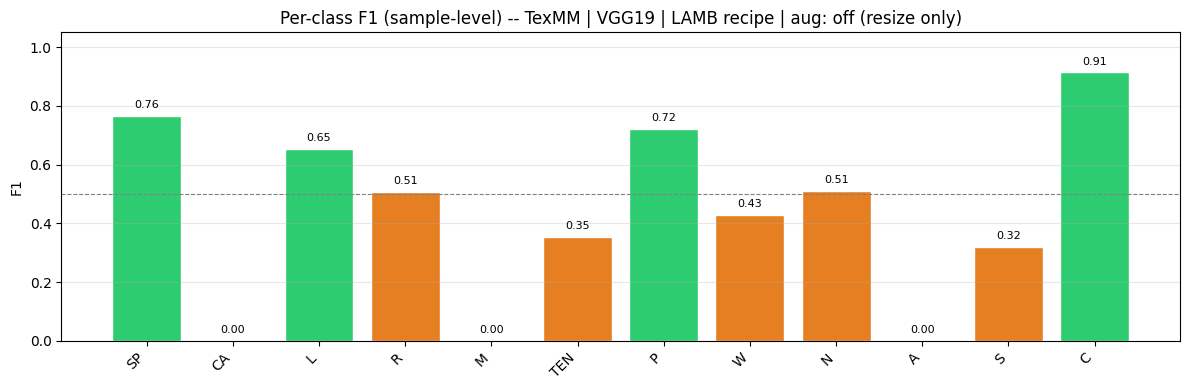

In [ ]:
per_f1 = f1_score(L, P, average=None, zero_division=0)
fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES), 4))
colors = ['#2ecc71' if f > 0.6 else '#e67e22' if f > 0.3 else '#e74c3c' for f in per_f1]
bars = ax.bar(CLASSES, per_f1, color=colors, edgecolor='white')
ax.axhline(0.5, color='grey', ls='--', lw=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel('F1'); ax.set_title('Per-class F1 (sample-level) -- ' + RUN_NAME)
ax.grid(alpha=0.3, axis='y')
for b, v in zip(bars, per_f1):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=8)
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('/content/per_class_f1.png', dpi=150, bbox_inches='tight'); plt.show()

## 15 · Save artefacts to Drive

In [ ]:
os.makedirs(SAVE_DIR, exist_ok=True)
saved = []
for src, dst in [(CKPT_PATH, RUN_TAG + '.pt'),
                 ('/content/curves.png', RUN_TAG + '_curves.png'),
                 ('/content/per_class_f1.png', RUN_TAG + '_per_class_f1.png')]:
    if os.path.exists(src):
        shutil.copy(src, os.path.join(SAVE_DIR, dst)); saved.append(dst)
print('Saved to', SAVE_DIR, '->', saved)

Saved to /content/drive/MyDrive/TexMM_Local -> ['texmm_vgg19_lamb_hires448_cosine.pt', 'texmm_vgg19_lamb_hires448_cosine_curves.png', 'texmm_vgg19_lamb_hires448_cosine_per_class_f1.png']
